In [1]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt
import numpy as np

In [33]:
x,y = make_classification(n_samples=100,n_features=2,n_redundant=0,n_informative=1,
                          n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,class_sep=30)

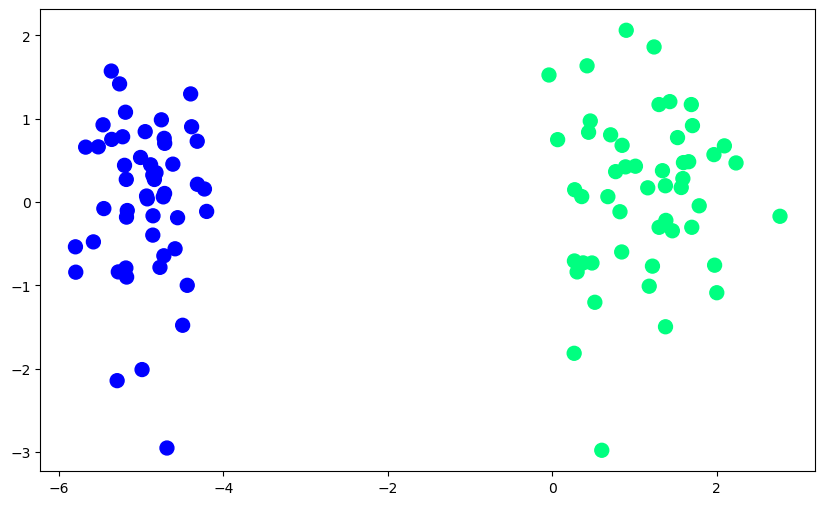

In [14]:
plt.figure(figsize=(10,6))
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100)

In [19]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression(penalty=None,solver='sag')
lor.fit(x,y)


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,penalty,None
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'sag'
,max_iter,100
,multi_class,'deprecated'


In [20]:
m = -(lor.coef_[0][0]/lor.coef_[0][1])
b = -(lor.intercept_/lor.coef_[0][1])

In [55]:
m,b

(np.float64(-22.519571975810813), array([-23.59094885]))

In [56]:
lor.coef_,lor.intercept_

(array([[3.97770138, 0.17663308]]), array([4.16694198]))

In [21]:
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input1 + b

(-3.0, 2.0)

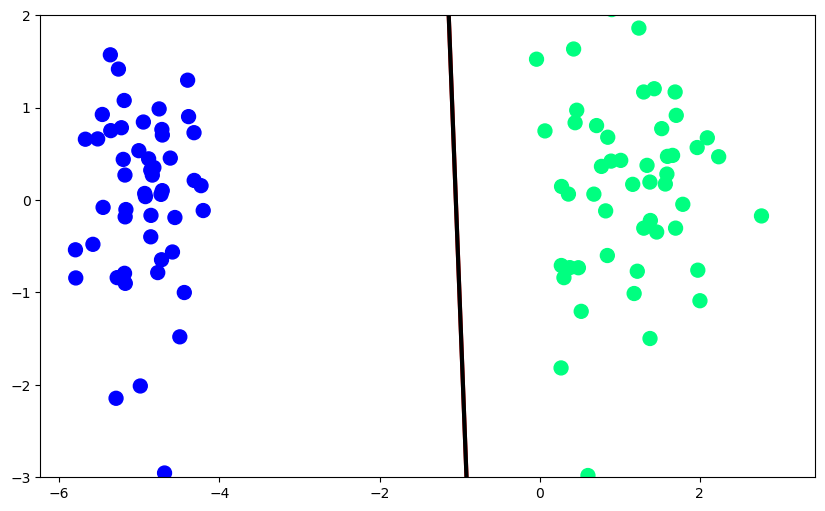

In [22]:
plt.figure(figsize=(10,6))
plt.plot(x_input1,y_input1,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [78]:
def gd(x,y):
    x = np.insert(x,0,1,axis=1)
    weight = np.ones(x.shape[1])
    lr = 0.5

    for i in range (3000):
        y_hat = sigmoid(np.dot(x,weight))
        weight = weight + lr * (np.dot((y-y_hat),x)/x.shape[0])

    return weight[1:],weight[0]

In [79]:
def sigmoid(z):
    return 1/(1 + np.exp(-z))

In [80]:
coef_1,inter_ = gd(x,y)

In [81]:
coef_1,inter_

(array([3.29738965, 0.12297964]), np.float64(4.669050984110743))

In [82]:
lor.coef_,lor.intercept_

(array([[3.97770138, 0.17663308]]), array([4.16694198]))

In [83]:
m1 = -(coef_1[0]/coef_1[1])
b1 = -(inter_/coef_1[1])

In [84]:
x_input2 = np.linspace(-3,3,100)
y_input2 = m1*x_input1 + b1

(-3.0, 2.0)

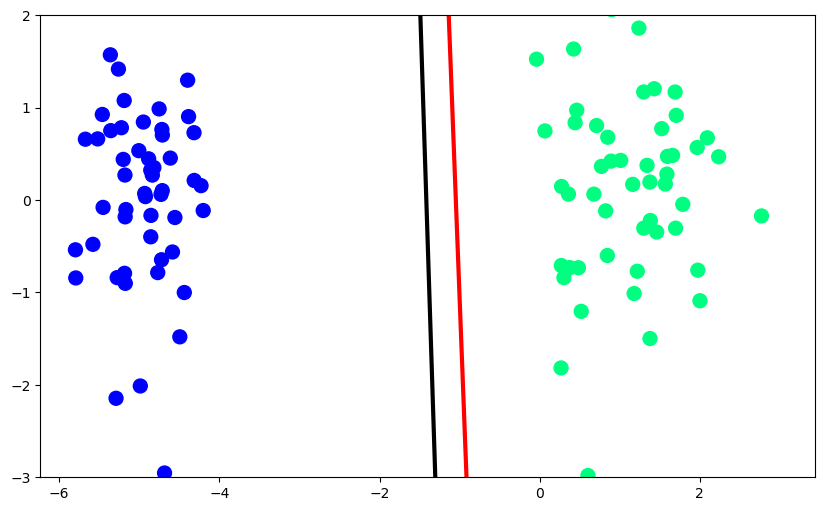

In [85]:
plt.figure(figsize=(10,6))
plt.plot(x_input1,y_input1,color='red',linewidth=3)
plt.plot(x_input2,y_input2,color='black',linewidth=3)
plt.scatter(x[:,0],x[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)